# 02 – Logistic Regression
Logistic Regression model for predicting hotel booking cancellations (MS26926476).
We use the train/test split that was created in notebook 01.

Logistic regression takes a weighted sum of the features and puts it through the sigmoid function. This gives a probability between 0 and 1 that the booking will be canceled. If the probability is 0.5 or higher, the booking is predicted as canceled.

We chose this model because our target `is_canceled` only has two values (0 or 1), and logistic regression is the standard model for this kind of problem. It is also easy to explain: each coefficient shows whether a feature makes a cancellation more or less likely. Since it gives probabilities, the hotel could also change the 0.5 threshold depending on what is more costly for them. It also trains in a few seconds, so it is a good simple model to start with.

The main weakness is that it assumes a linear relationship between the features and the log-odds of cancellation, so it can miss more complex patterns. It also needs the numeric features to be scaled.

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, precision_recall_curve)

RANDOM_STATE = 42

In [2]:
# load the train/test sets created in notebook 01 (same split for both models)
train = pd.read_csv("../outputs/train.csv")
test = pd.read_csv("../outputs/test.csv")

X_train = train.drop(columns=["is_canceled"])
y_train = train["is_canceled"]
X_test = test.drop(columns=["is_canceled"])
y_test = test["is_canceled"]

print(X_train.shape, X_test.shape)

(69767, 31) (17442, 31)


## Removing overlapping columns
Logistic regression gives one coefficient to every feature. When two columns contain the same information, the model can split the effect between them in strange ways and the coefficients are hard to read. So for this model we removed a few columns:

`total_nights` is just `stays_in_weekend_nights` + `stays_in_week_nights`, and `total_guests` is `adults` + `children` + `babies`. We kept the totals and dropped the parts.
`arrival_date_week_number` tells the model the same thing as `arrival_date_month`. When we kept both, the month coefficients became very large with opposite signs, so we dropped the week number.
We also dropped `arrival_date_year`, because the hotel would use the model on future years that are not in the data.

In [3]:
drop_cols = ["stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
             "arrival_date_week_number", "arrival_date_year"]
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical:", cat_cols)
print("Numeric:", num_cols)

Categorical: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']
Numeric: ['lead_time', 'arrival_date_day_of_month', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'has_company', 'has_agent', 'total_guests', 'total_nights', 'has_previous_cancellation']


## Baseline model
First we train a logistic regression with the default settings as a starting point.

Logistic regression needs the numeric columns to be scaled. Columns like `lead_time` and `adr` have much bigger values than the 0/1 columns, so without scaling the regularisation would affect them differently and their coefficients could not be compared. We use StandardScaler to give all numeric columns a mean of 0 and a standard deviation of 1. The model can only work with numbers, so the text columns are one-hot encoded, and categories with fewer than 50 bookings are grouped together. Both steps are inside a pipeline, so they only learn from the training data.

In [4]:
# scale numeric columns, one-hot encode text columns
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
    ("num", StandardScaler(), num_cols),
])

lr_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE)),
])

In [5]:
def evaluate(model, X_train, y_train, X_test, y_test, threshold=0.5):
    """Print train accuracy and test metrics for a fitted classifier."""
    train_prob = model.predict_proba(X_train)[:, 1]
    y_prob = model.predict_proba(X_test)[:, 1]   # probability of "canceled"
    y_pred = (y_prob >= threshold).astype(int)
    results = {
        "Train accuracy": accuracy_score(y_train, (train_prob >= threshold).astype(int)),
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }
    for name, value in results.items():
        print(f"{name:<15}: {float(value):.4f}")
    return results

start = time.time()
lr_pipeline.fit(X_train, y_train)
print("Training time:", round(time.time() - start, 1), "s")
baseline_results = evaluate(lr_pipeline, X_train, y_train, X_test, y_test)

Training time: 2.0 s


Train accuracy : 0.7940
Test accuracy  : 0.7969
Precision      : 0.6871
Recall         : 0.4802
F1-score       : 0.5653
ROC-AUC        : 0.8383


## Hyperparameter tuning
The baseline does not overfit, but it only finds about half of the cancellations (recall 0.48). We tuned three settings with grid search and stratified 3-fold cross-validation on the training set. We used F1-score to pick the best model, because the classes are imbalanced and accuracy alone would look good even if the model missed many cancellations.

The penalty can be L2, which makes all coefficients smaller, or L1, which can set some coefficients to exactly 0. C controls how strong the regularisation is (a smaller C means stronger regularisation). `class_weight="balanced"` gives more weight to the canceled bookings because there are fewer of them.

In [6]:
# newer scikit-learn versions (1.8+) use l1_ratio instead of penalty: 0 = L2, 1 = L1
if int(sklearn.__version__.split(".")[1]) >= 8:
    penalty = {"model__l1_ratio": [0, 1]}
else:
    penalty = {"model__penalty": ["l2", "l1"]}

param_grid = {
    **penalty,
    "model__C": [0.001, 0.01, 0.1, 1],          # we left out C > 1 because L1 took very long to train
    "model__class_weight": [None, "balanced"],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search = GridSearchCV(lr_pipeline, param_grid, scoring="f1", cv=cv,
                      n_jobs=-1, return_train_score=True)

start = time.time()
search.fit(X_train, y_train)
print("Tuning time:", round(time.time() - start, 1), "s")
print("Best parameters:", search.best_params_)
print("Best CV F1:", round(search.best_score_, 4))

Tuning time: 56.7 s
Best parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__l1_ratio': 0}
Best CV F1: 0.6248


In [7]:
# results of all 16 combinations, best first
cv_table = pd.DataFrame(search.cv_results_)
penalty_col = [c for c in cv_table.columns if c in ("param_model__l1_ratio", "param_model__penalty")][0]
cv_table["penalty"] = cv_table[penalty_col].replace({0: "L2", 1: "L1", "l2": "L2", "l1": "L1"})
cv_table["class_weight"] = cv_table["param_model__class_weight"].fillna("None")
cv_table["C"] = cv_table["param_model__C"]
cv_table["Train F1"] = cv_table["mean_train_score"]
cv_table["CV F1"] = cv_table["mean_test_score"]
cv_table = cv_table[["penalty", "C", "class_weight", "Train F1", "CV F1"]].sort_values("CV F1", ascending=False)
cv_table.round(4)

,penalty,C,class_weight,Train F1,CV F1
10,L2,0.100,balanced,0.6264,0.6248
11,L1,0.100,balanced,0.6257,0.6246
15,L1,1.000,balanced,0.6265,0.6241
6,L2,0.010,balanced,0.6243,0.6240
14,L2,1.000,balanced,0.6264,0.6238
7,L1,0.010,balanced,0.6169,0.6168
2,L2,0.001,balanced,0.6123,0.6113
3,L1,0.001,balanced,0.5757,0.5753
12,L2,1.000,None,0.5565,0.5544
13,L1,1.000,None,0.5565,0.5542


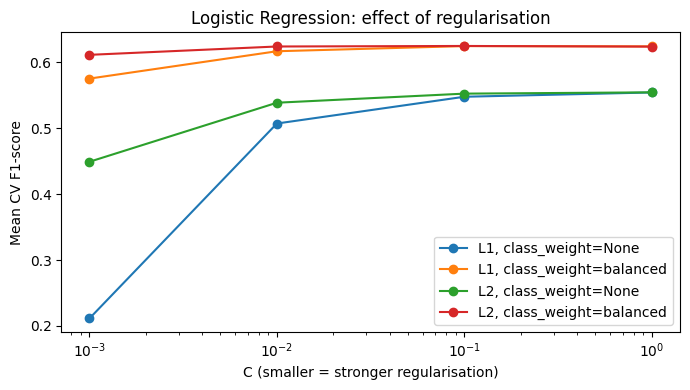

In [8]:
# how the CV F1-score changes with C
fig, ax = plt.subplots(figsize=(7, 4))
for (pen, cw), group in cv_table.groupby(["penalty", "class_weight"]):
    group = group.sort_values("C")
    ax.plot(group["C"].astype(float), group["CV F1"], marker="o", label=f"{pen}, class_weight={cw}")
ax.set_xscale("log")
ax.set_xlabel("C (smaller = stronger regularisation)")
ax.set_ylabel("Mean CV F1-score")
ax.set_title("Logistic Regression: effect of regularisation")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/lr_regularisation.png", dpi=300, bbox_inches="tight")
plt.show()

## Tuned model: test-set evaluation
Now we evaluate the best model from the search once on the test set.

In [9]:
best_lr = search.best_estimator_   # already refit on the full training set
tuned_results = evaluate(best_lr, X_train, y_train, X_test, y_test)

tn, fp, fn, tp = confusion_matrix(y_test, best_lr.predict(X_test)).ravel()
print()
print(f"Canceled bookings found: {tp} of {tp + fn} (missed {fn})")
print("False alarms:", fp, "of", tn + fp, "non-canceled bookings")

Train accuracy : 0.7455
Test accuracy  : 0.7456
Precision      : 0.5256
Recall         : 0.7722
F1-score       : 0.6255
ROC-AUC        : 0.8381

Canceled bookings found: 3705 of 4798 (missed 1093)
False alarms: 3344 of 12644 non-canceled bookings


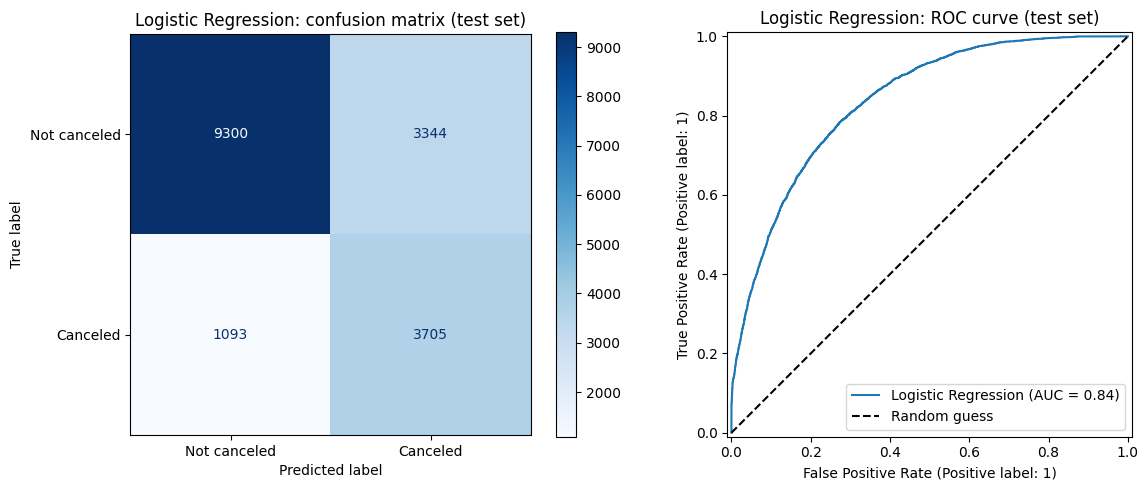

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    best_lr, X_test, y_test, display_labels=["Not canceled", "Canceled"],
    cmap="Blues", ax=axes[0])
axes[0].set_title("Logistic Regression: confusion matrix (test set)")

RocCurveDisplay.from_estimator(best_lr, X_test, y_test, ax=axes[1], name="Logistic Regression")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("Logistic Regression: ROC curve (test set)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/lr_confusion_roc.png", dpi=300, bbox_inches="tight")
plt.show()

## Changing the threshold
Because logistic regression gives a probability, we don't have to use 0.5 as the cut-off. A lower threshold finds more cancellations but also gives more false alarms. A higher threshold does the opposite.

We didn't want to use the test set to choose the threshold, so we used cross-validated predictions on the training set and took the threshold with the highest F1-score.

Threshold with the highest CV F1: 0.542


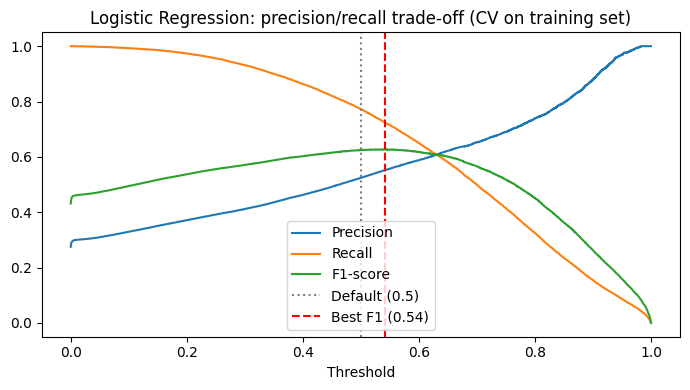

In [11]:
train_prob = cross_val_predict(best_lr, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, train_prob)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
best_threshold = float(thresholds[np.argmax(f1)])
print("Threshold with the highest CV F1:", round(best_threshold, 3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, precision[:-1], label="Precision")
ax.plot(thresholds, recall[:-1], label="Recall")
ax.plot(thresholds, f1, label="F1-score")
ax.axvline(0.5, color="grey", linestyle=":", label="Default (0.5)")
ax.axvline(best_threshold, color="red", linestyle="--", label=f"Best F1 ({best_threshold:.2f})")
ax.set_xlabel("Threshold")
ax.set_title("Logistic Regression: precision/recall trade-off (CV on training set)")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/lr_threshold.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# test results with the new threshold
threshold_results = evaluate(best_lr, X_train, y_train, X_test, y_test, threshold=best_threshold)

Train accuracy : 0.7643
Test accuracy  : 0.7634
Precision      : 0.5537
Recall         : 0.7224
F1-score       : 0.6269
ROC-AUC        : 0.8381


## Coefficients
A positive coefficient means the feature makes a cancellation more likely, and a negative one means less likely. If we take exp(coefficient) we get the odds ratio. For example, an odds ratio of 2 means the odds of cancellation are doubled.

The numeric features were scaled, so their coefficients are for one standard deviation. To make them easier to understand, we converted some of them back to normal units (days, euros, etc.).

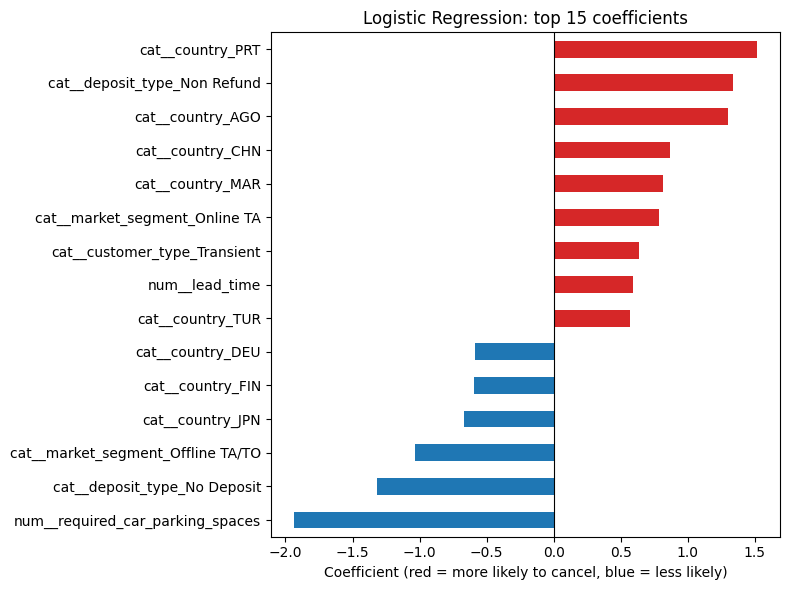

,coefficient,odds ratio
num__required_car_parking_spaces,-1.937,0.144
cat__country_PRT,1.517,4.557
cat__deposit_type_Non Refund,1.336,3.803
cat__deposit_type_No Deposit,-1.320,0.267
cat__country_AGO,1.298,3.663
cat__market_segment_Offline TA/TO,-1.035,0.355
cat__country_CHN,0.869,2.385
cat__country_MAR,0.814,2.257
cat__market_segment_Online TA,0.788,2.198
cat__country_JPN,-0.665,0.514


In [13]:
feature_names = best_lr.named_steps["preprocess"].get_feature_names_out()
coefs = pd.Series(best_lr.named_steps["model"].coef_.ravel(), index=feature_names)

top15 = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
colors = ["tab:red" if c > 0 else "tab:blue" for c in top15.sort_values()]
top15.sort_values().plot(kind="barh", figsize=(8, 6), color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression: top 15 coefficients")
plt.xlabel("Coefficient (red = more likely to cancel, blue = less likely)")
plt.tight_layout()
plt.savefig("../figures/lr_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

pd.DataFrame({"coefficient": top15, "odds ratio": np.exp(top15)}).round(3)

In [14]:
# odds ratios in normal units: exp(units * coefficient / standard deviation)
scaler = best_lr.named_steps["preprocess"].named_transformers_["num"]
std = pd.Series(scaler.scale_, index=num_cols)

def odds_ratio(col, units):
    return np.exp(units * coefs["num__" + col] / std[col])

print("+30 days lead time:      ", round(odds_ratio("lead_time", 30), 3))
print("+1 special request:      ", round(odds_ratio("total_of_special_requests", 1), 3))
print("+1 booking change:       ", round(odds_ratio("booking_changes", 1), 3))
print("+10 EUR adr:             ", round(odds_ratio("adr", 10), 3))
print("+1 night:                ", round(odds_ratio("total_nights", 1), 3))

+30 days lead time:       1.231
+1 special request:       0.519
+1 booking change:        0.761
+10 EUR adr:              1.078
+1 night:                 1.075


In [15]:
# required_car_parking_spaces has the biggest coefficient,
# because none of the bookings with a parking space were canceled
train.groupby(train["required_car_parking_spaces"] > 0)["is_canceled"].agg(["mean", "count"]).round(4)

,mean,count
required_car_parking_spaces,,
False,0.3001,63955
True,0.0000,5812


In [16]:
# previous cancellations: the count and has_previous_cancellation overlap, so their
# coefficients cancel each other out a bit. Looking at the raw rates is clearer
train.groupby("previous_cancellations")["is_canceled"].agg(["mean", "count"]).round(3).head(8)

,mean,count
previous_cancellations,,
0,0.267,68420
1,0.748,1120
2,0.344,93
3,0.283,46
4,0.174,23
5,0.125,16
6,0.083,12
11,0.080,25


In [17]:
# save metrics so notebook 04 can compare both models
results_df = pd.DataFrame([baseline_results, tuned_results, threshold_results],
                          index=["LR baseline", "LR tuned", f"LR tuned (threshold {best_threshold:.2f})"])
results_df.to_csv("../outputs/lr_results.csv")
results_df.round(4)

,Train accuracy,Test accuracy,Precision,Recall,F1-score,ROC-AUC
LR baseline,0.7940,0.7969,0.6871,0.4802,0.5653,0.8383
LR tuned,0.7455,0.7456,0.5256,0.7722,0.6255,0.8381
LR tuned (threshold 0.54),0.7643,0.7634,0.5537,0.7224,0.6269,0.8381


**Tuned vs. Baseline Model**

The baseline model did not overfit (train accuracy 0.794 and test accuracy 0.797), but it only found 48% of the cancellations. The best tuned model used L2 regularisation with C = 0.1 and `class_weight="balanced"`. The class weight was the setting that made the biggest difference: all the balanced models had a CV F1 of around 0.61–0.62, while the others were between 0.45 and 0.55. L1 or L2 and the value of C did not change much, except for C = 0.001, where the model was too simple. The train and CV F1 were almost the same in every case, so logistic regression does not overfit on this data.

After tuning, recall went up from 0.48 to 0.77 and F1-score from 0.57 to 0.63. Precision went down from 0.69 to 0.53, so the model now gives more false alarms. ROC-AUC stayed at 0.84, because the class weight changes where the model draws the line, but not the order in which it ranks the bookings.

**Confusion Matrix**

On the test set, the tuned model found 3,705 of the 4,798 canceled bookings and missed 1,093. It also predicted a cancellation for 3,344 of the 12,644 bookings that were not canceled.

**Threshold**

The best threshold from cross-validation was 0.54, which is close to 0.5. On the test set it gave almost the same F1-score (0.627 vs. 0.626), with a bit higher precision (0.55) and lower recall (0.72). If an empty room costs the hotel more than a false alarm, it would be better to use a lower threshold instead.

**Coefficients**

No booking with a parking space request was canceled (0 out of 5,812 in the training set), which is why `required_car_parking_spaces` has the largest negative coefficient. `Non Refund` deposits had a high odds ratio (3.8), which matches the strange pattern we saw in the EDA. This is a correlation and does not mean that the deposit causes the cancellation. Guests from Portugal (`country_PRT`) were also much more likely to cancel (odds ratio 4.6).

For the numeric features, every extra 30 days of lead time increases the odds of cancellation by about 23%. Each special request lowers the odds by about 48%, and each booking change by about 24%.

Guests with one previous cancellation canceled again 75% of the time, compared to 27% for guests with no previous cancellations. But guests with many previous cancellations almost never canceled, so the effect is not linear.

**Limitations**

Logistic regression can only learn linear relationships, so it cannot properly capture patterns like the previous cancellations one above, or interactions between features (for example lead time and market segment).